# Transformers


#### A Transformer is a deep learning architecture designed to process sequences of text using self-attention.

- Transformers are the foundation of many modern NLP models, including BERT, GPT, and T5.

- Before Transformers, we used models such as RNNs and LSTMs for NLP tasks.

<img src="https://drive.google.com/thumbnail?id=1unPqGaKftHxp37-F99Bg6hJzFbQdCGC7&sz=w1000" width="700">

In [1]:
%pip -q install transformers torch matplotlib

Note: you may need to restart the kernel to use updated packages.


## 1. Load a Transformer

We use **DistilBERT**, a  Transformer fine-tuned for positive/negative sentiment classification.

In [2]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch

model_name = "distilbert-base-uncased-finetuned-sst-2-english"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(model_name)
model.eval()

# Look inside the Transformer architecture.
print("Transformer layers:", model.config.n_layers)
print("Attention heads per layer:", model.config.n_heads)
print("Hidden size:", model.config.dim)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Transformer layers: 6
Attention heads per layer: 12
Hidden size: 768



<img src="https://drive.google.com/thumbnail?id=1v2dRK1KR_ydZOknjj8Xv8_wjOdXleDYs&sz=w1000" width="500">

## 2. Tokenizing the text

In [3]:
sentence = "The movie was not good."

# Tokenization: converts text into token IDs
inputs = tokenizer(sentence, return_tensors="pt")

# [CLS] = start token, [SEP] = end token
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

print("Tokens:", tokens)

Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']


## 3. Embeddings and self-attention

Each token ID becomes a **vector (embedding)**. Inside each Transformer layer, **self-attention** lets a token use information from other tokens in the same sentence.

In [4]:
import torch

# Enable attention weights
model.set_attn_implementation("eager")

with torch.no_grad():
    embeddings = model.distilbert.embeddings(inputs["input_ids"])
    outputs = model(**inputs, output_attentions=True)

# Attention from the first layer and first head
attention = outputs.attentions[0][0, 0]

print("Embeddings shape:", embeddings.shape)
print("Attention shape:", attention.shape)
print("Tokens:", tokens)
print("Attention weights:\n", attention)

Embeddings shape: torch.Size([1, 8, 768])
Attention shape: torch.Size([8, 8])
Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']
Attention weights:
 tensor([[0.1145, 0.0938, 0.0681, 0.0701, 0.0596, 0.0800, 0.1593, 0.3546],
        [0.4147, 0.0793, 0.0481, 0.1018, 0.1084, 0.0805, 0.0789, 0.0883],
        [0.1634, 0.0327, 0.0975, 0.0403, 0.1819, 0.1402, 0.0866, 0.2574],
        [0.2882, 0.1014, 0.0504, 0.0669, 0.2180, 0.1009, 0.1231, 0.0511],
        [0.3612, 0.0501, 0.0696, 0.1200, 0.0642, 0.1304, 0.0953, 0.1092],
        [0.3065, 0.0469, 0.1175, 0.1915, 0.0630, 0.0555, 0.1120, 0.1071],
        [0.3505, 0.0935, 0.0572, 0.0753, 0.0972, 0.0964, 0.1165, 0.1135],
        [0.3513, 0.1019, 0.0318, 0.0541, 0.1036, 0.0607, 0.0755, 0.2210]])


## 4. Classification: From Transformer to prediction

The Transformer produces contextual representations. The **classification head** turns them into two scores (*logits*). **Softmax** converts these into probabilities that sum to 1.

In [5]:
# Get prediction scores from the Transformer
with torch.no_grad():
    logits = model(**inputs).logits

# Convert scores into probabilities
probs = torch.softmax(logits, dim=1)[0]

# Display the prediction
prediction = probs.argmax().item()

print("Prediction:", model.config.id2label[prediction])
print("Confidence:", round(probs[prediction].item(), 3))


Prediction: NEGATIVE
Confidence: 1.0



### Task: Exploring Transformer Layers and Attention Heads

Load the pretrained **`bert-base-uncased`** model using Hugging Face Transformers.

1. Write code to print the number of Transformer layers and the number of attention heads per layer.
2. Calculate and print the total number of attention heads across all Transformer layers.
3. Using the sentence `"Transformers use self-attention to understand language."`, extract the attention weights from the **third Transformer layer and second attention head**.
4. Explain what the rows and columns of the attention matrix represent.

### Steps 1 and 2 &mdash; Load `bert-base-uncased` and count the attention heads

In [6]:
# Steps 1 and 2: load bert-base-uncased, then count its layers and attention heads
from transformers import AutoTokenizer, AutoModel
import torch

bert_name = "bert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(bert_name)

# "eager" attention is required for the model to return the attention weights
try:
    bert_model = AutoModel.from_pretrained(bert_name, attn_implementation="eager")
except TypeError:
    # Older versions of transformers do not accept the argument
    bert_model = AutoModel.from_pretrained(bert_name)
    bert_model.set_attn_implementation("eager")

bert_model.eval()

# 1. Number of Transformer layers and attention heads per layer
num_layers = bert_model.config.num_hidden_layers
heads_per_layer = bert_model.config.num_attention_heads

print("Model:", bert_name)
print("Transformer layers          :", num_layers)
print("Attention heads per layer   :", heads_per_layer)
print("Hidden size                 :", bert_model.config.hidden_size)

# 2. Total number of attention heads across all layers
total_heads = num_layers * heads_per_layer
print(f"Total attention heads       : {num_layers} x {heads_per_layer} = {total_heads}")

# Each head works on a slice of the hidden vector
print("Dimension of each head      :",
      bert_model.config.hidden_size // heads_per_layer)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

c:\Users\ahmad\miniconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ahmad\.cache\huggingface\hub\models--bert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

c:\Users\ahmad\miniconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ahmad\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Model: bert-base-uncased
Transformer layers          : 12
Attention heads per layer   : 12
Hidden size                 : 768
Total attention heads       : 12 x 12 = 144
Dimension of each head      : 64


### Step 3 &mdash; Attention weights from the third layer, second head

In [7]:
# Step 3: extract the attention weights of the third layer and the second head
bert_sentence = "Transformers use self-attention to understand language."

bert_inputs = bert_tokenizer(bert_sentence, return_tensors="pt")
bert_tokens = bert_tokenizer.convert_ids_to_tokens(bert_inputs["input_ids"][0])

with torch.no_grad():
    bert_outputs = bert_model(**bert_inputs, output_attentions=True)

# outputs.attentions is a tuple with one entry per layer.
# Each entry has the shape (batch, heads, sequence, sequence).
print("Number of layers returned :", len(bert_outputs.attentions))
print("Shape of one layer        :", tuple(bert_outputs.attentions[0].shape))
print()

# Python counts from 0, so the THIRD layer is index 2 and the SECOND head is index 1
layer_index = 2
head_index = 1

attention_3_2 = bert_outputs.attentions[layer_index][0, head_index]

print("Sentence :", bert_sentence)
print("Tokens   :", bert_tokens)
print("Number of tokens :", len(bert_tokens))
print()
print(f"Attention of layer {layer_index + 1}, head {head_index + 1}")
print("Shape :", tuple(attention_3_2.shape))
print(attention_3_2)

Number of layers returned : 12
Shape of one layer        : (1, 12, 11, 11)

Sentence : Transformers use self-attention to understand language.
Tokens   : ['[CLS]', 'transformers', 'use', 'self', '-', 'attention', 'to', 'understand', 'language', '.', '[SEP]']
Number of tokens : 11

Attention of layer 3, head 2
Shape : (11, 11)
tensor([[7.3176e-01, 7.9132e-03, 1.0591e-02, 5.5538e-03, 1.6532e-02, 6.8604e-03,
         1.0085e-02, 1.1588e-02, 5.5202e-03, 3.8613e-02, 1.5499e-01],
        [8.8883e-01, 4.7016e-03, 3.4382e-02, 1.7840e-04, 2.7377e-03, 5.0542e-03,
         9.0185e-04, 7.3192e-04, 4.0114e-04, 5.1106e-03, 5.6975e-02],
        [1.4273e-01, 5.6892e-01, 5.4059e-03, 3.5340e-02, 4.1156e-02, 6.7886e-02,
         8.9602e-02, 3.2741e-04, 5.3299e-03, 8.9671e-03, 3.4334e-02],
        [3.3953e-01, 7.3164e-02, 1.5250e-03, 1.6106e-04, 2.0160e-01, 8.1124e-02,
         6.3570e-02, 2.5709e-02, 1.6392e-03, 2.8494e-02, 1.8348e-01],
        [1.4291e-01, 6.9677e-02, 7.1289e-02, 6.3943e-01, 1.2104e-02,

Rows = the token that is attending, columns = the token being attended to



,[CLS],transformers,use,self,-,attention,to,understand,language,.,[SEP]
[CLS],0.732,0.008,0.011,0.006,0.017,0.007,0.010,0.012,0.006,0.039,0.155
transformers,0.889,0.005,0.034,0.000,0.003,0.005,0.001,0.001,0.000,0.005,0.057
use,0.143,0.569,0.005,0.035,0.041,0.068,0.090,0.000,0.005,0.009,0.034
self,0.340,0.073,0.002,0.000,0.202,0.081,0.064,0.026,0.002,0.028,0.183
-,0.143,0.070,0.071,0.639,0.012,0.013,0.003,0.003,0.014,0.009,0.022
attention,0.113,0.545,0.012,0.020,0.111,0.010,0.072,0.000,0.000,0.016,0.100
to,0.084,0.022,0.622,0.008,0.009,0.194,0.011,0.007,0.001,0.014,0.027
understand,0.434,0.005,0.002,0.022,0.012,0.003,0.330,0.002,0.055,0.053,0.082
language,0.051,0.001,0.429,0.002,0.004,0.001,0.005,0.398,0.006,0.041,0.062
.,0.658,0.006,0.003,0.001,0.004,0.003,0.009,0.038,0.046,0.073,0.159



Sum of each row:
[CLS]           1.0
transformers    1.0
use             1.0
self            1.0
-               1.0
attention       1.0
to              1.0
understand      1.0
language        1.0
.               1.0
[SEP]           1.0


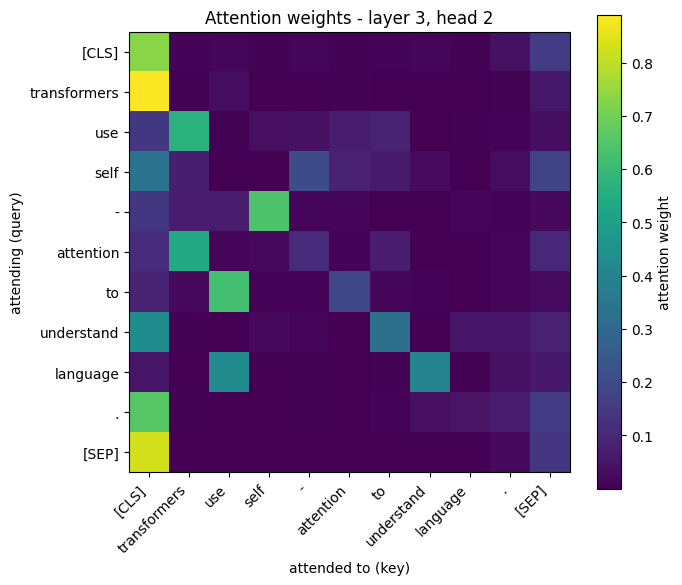


The token each word gives the most attention to:
  [CLS]          -> [CLS]          (0.7318)
  transformers   -> [CLS]          (0.8888)
  use            -> transformers   (0.5689)
  self           -> [CLS]          (0.3395)
  -              -> self           (0.6394)
  attention      -> transformers   (0.5448)
  to             -> use            (0.6222)
  understand     -> [CLS]          (0.4336)
  language       -> use            (0.4292)
  .              -> [CLS]          (0.6580)
  [SEP]          -> [CLS]          (0.8278)


In [8]:
# The same matrix with the tokens as labels, which makes it readable
import pandas as pd
import matplotlib.pyplot as plt

attention_table = pd.DataFrame(attention_3_2.numpy(),
                               index=bert_tokens, columns=bert_tokens)

print("Rows = the token that is attending, columns = the token being attended to\n")
display(attention_table.round(3))

# Every row is a probability distribution, so every row adds up to 1
print("\nSum of each row:")
print(attention_table.sum(axis=1).round(4).to_string())

# A heat map of the same numbers
fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(attention_3_2.numpy(), cmap="viridis")

ax.set_xticks(range(len(bert_tokens)))
ax.set_yticks(range(len(bert_tokens)))
ax.set_xticklabels(bert_tokens, rotation=45, ha="right")
ax.set_yticklabels(bert_tokens)
ax.set_xlabel("attended to (key)")
ax.set_ylabel("attending (query)")
ax.set_title(f"Attention weights - layer {layer_index + 1}, head {head_index + 1}")

fig.colorbar(image, ax=ax, label="attention weight")
plt.tight_layout()
plt.show()

# The strongest connection for each token
print("\nThe token each word gives the most attention to:")
for token in bert_tokens:
    row = attention_table.loc[token]
    print(f'  {token:<14} -> {row.idxmax():<14} ({row.max():.4f})')

### Step 4 &mdash; What the rows and the columns represent

The attention matrix is square: its size is `(number of tokens x number of tokens)`, so for
this sentence it is an `11 x 11` matrix, one row and one column for every token including
`[CLS]` and `[SEP]`.

**The rows are the token that is doing the attending (the *query*).**
Row *i* answers one question: *while this head builds the new representation of token i, how
much does it take from each of the other tokens?* Reading row `understand` from left to right
shows where that word looked across the whole sentence.

**The columns are the token being attended to (the *key* and *value*).**
Column *j* answers the opposite question: *how much did every other token draw from token j?*
A column with large values everywhere is a token the whole sentence relies on, which is usually
`[CLS]` or `[SEP]`.

**Cell (i, j)** is therefore a single number: the weight that token *i* places on token *j*.

Three properties follow from how the weights are produced:

1. **Every row sums to 1**, because a softmax is applied across each row. The columns do not
   sum to 1 &mdash; a token can be heavily used by many tokens at once, or by none.

2. **The matrix is not symmetric.** Cell (i, j) and cell (j, i) are different numbers, since
   *understand* taking information from *language* is a separate decision from *language*
   taking information from *understand*.

3. **The diagonal is a real value, not a special case.** A token attends to itself like any
   other position, and in several heads that self-weight is small.

One more point about the weights in the output above: a large share of the attention goes to
`[CLS]` and `[SEP]`. This is a known behaviour of BERT rather than a fault &mdash; when a head
has nothing useful to do for a given token, it dumps its weight on these two separator tokens,
which carry no word meaning. The softmax forces the row to add up to 1, so the weight has to
go somewhere, and these tokens act as the place to put it.

Finally, this is **one head out of 144** (12 layers x 12 heads). Different heads learn
different relations &mdash; some follow the next token, some link a verb to its subject, some
track punctuation &mdash; so the matrix above is one view of the sentence, not the model's
complete reading of it.